# More regression with Bayes

## Introduction

Still more regression examples from Bayesian Analysis with Python (Edition 3).  This  time, a dataset with a bad case of Heteroskedasticity.  We have a dataset where we measure baby length:  as babies get longer, so the variance grows (the gap between between the longest and shortest baby gets bigger as they get older)

We develop a model that tries to capture this behaviour.

I also learn a lot about PyMC extrapolation / prediction, and how to frame the model specification to accommodate this

---------------------------

## Implementation

### Imports

In [4]:
import pathlib

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import preliz as pz
import pymc as pm
import xarray as xa

--------------------

## Load dataset

In [5]:
path = pathlib.Path("data/babies.csv")
df = pd.read_csv(path)
print(df.head(2))

   month     length
0      0  49.192857
1      0  51.221429


### Visualize dataset

We can clearly see that the spread of baby lengths get bigger as they get older

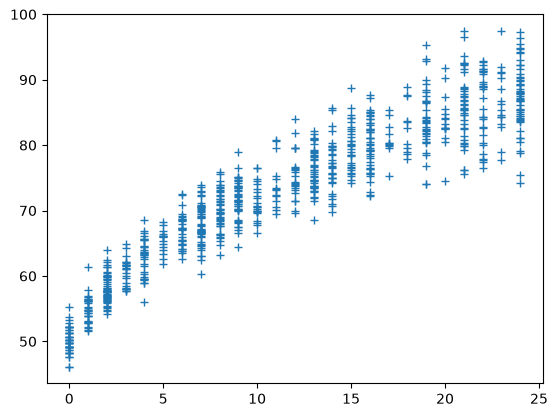

In [6]:
plt.plot(df["month"], df["length"], "+")

-------------------

## Build and run linear model

In order to contrast with a more nuanced model, we first build the simplest linear model: constant variance, length linearly dependent on age.

Some points to note:

- We use _pm.Data()_ call to store our dataset.  Later, we will change the _month_ Data collection, so the model (PyMC) will recalculate predictions for the new _month_ values.
- We explicitly set the length of the vector of length predictions (```l_pred```) as being the length of the _month_ dataset (```shape=month.shape```)
- We explicitly set the dimension name for ```l_pred``` to be the same as the automatically generated name for _month_.  This will make subsequent plotting and processing easier
- _l_err0_ is our linear model, to which we add Normal noise to get the _l_pred_ prediction
- We have __not__ normalized our data, and have chosen prior values for the linear model that make sense (by eye)

In [7]:
with pm.Model() as model_1:
    # store months and length in Data containers
    # later we will want to change months to get
    # out-of-sample predictions
    # the parameter shape=month.shape will allow us to change the months array,
    # to get predictions beyond the end of the data

    month = pm.Data("month", df.month)
    length = pm.Data("length", df.length)

    # set by eye
    intercept = pm.Normal("intercept", mu=55, sigma=100)

    # set by eye
    slope = pm.Normal("slope", mu=1.4, sigma=10)

    # set by eye
    error_sd = pm.HalfCauchy("error_sd", beta=10)

    # l_err0 is the line with no noise added
    l_err0 = pm.Deterministic("l_err0", intercept + slope * month)

    # l_pred is the linear model with added noise
    l_pred = pm.Normal(
        "l_pred",
        mu=l_err0,
        sigma=error_sd,
        observed=length,
        shape=month.shape,
        dims="month_dim_0",
    )

    idata_1 = pm.sample()
# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [intercept, slope, error_sd]


Output()

Visualize the model (look OK)

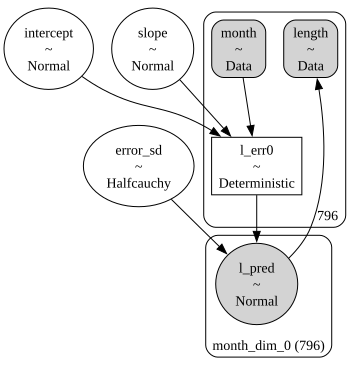

In [8]:
pm.model_to_graphviz(model_1)

Look for diagnostic problems (all OK)

In [9]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


------------------

Visualize the posterior distributions for the key parameters of the model

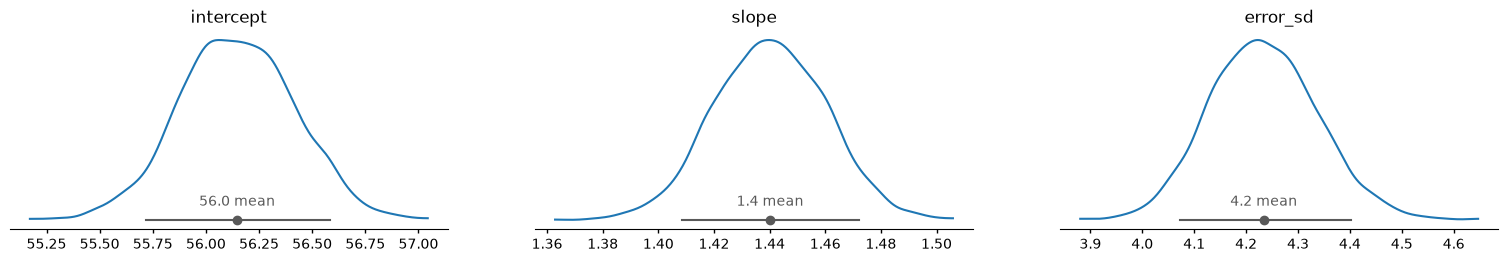

In [10]:
az.plot_dist(idata_1, var_names=["intercept", "slope", "error_sd"])

Examine the data structure resulting from our model run.  This will be extended below to support more analysis.  Note the absence of any Prior data

In [11]:
idata_1

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:       (chain: 4, draw: 1000, l_err0_dim_0: 796)
│       Coordinates:
│         * chain         (chain) int64 32B 0 1 2 3
│         * draw          (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
│         * l_err0_dim_0  (l_err0_dim_0) int64 6kB 0 1 2 3 4 5 ... 791 792 793 794 795
│       Data variables:
│           intercept     (chain, draw) float64 32kB 56.17 56.2 55.8 ... 55.51 55.93
│           slope         (chain, draw) float64 32kB 1.438 1.425 1.473 ... 1.476 1.445
│           error_sd      (chain, draw) float64 32kB 4.341 4.013 4.208 ... 4.288 4.187
│           l_err0        (chain, draw, l_err0_dim_0) float64 25MB 56.17 56.17 ... 90.61
│       Attributes:
│           created_at:                 2026-10-24T00:09:57.316014+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.2003464698791504
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 2 2 2 2 ... 2 3 3 3 3
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.7544 ... 0.7452
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.7534 0.7534 ... 0.715
│           mean_tree_accept          (chain, draw) float64 32kB 0.9689 0.7949 ... 1.0
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 0.03575 2.186 ... 2.665
│           transformation_index      (chain, draw) int64 32kB 338 338 338 ... 338 338
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-10-24T00:09:57.296718+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           month        (month_dim_0) int32 3kB 0 0 0 0 0 0 0 ... 24 24 24 24 24 24 24
│       Attributes:
│           created_at:                 2026-10-24T00:09:57.310432+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group: /observed_data
        Dimensions:      (month_dim_0: 796)
        Coordinates:
          * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
        Data variables:
            l_pred       (month_dim_0) fl

Get the key parameters in pandas DataFrame form, and then extract them from the pandas DataFrame 

In [12]:
results = az.summary(idata_1, var_names=["intercept", "slope"])
results

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,56.15,0.272,56,57,1349,1681,1.00,0.0074,0.0049
slope,1.44,0.02,1.4,1.5,1332,1518,1.00,0.00055,0.00036


In [13]:
line_a = results.loc["intercept", "mean"]
line_b = results.loc["slope", "mean"]
line_a, line_b

(np.float64(56.14674251118621), np.float64(1.440154543991303))

--------------------------------

## Prediction of in-sample values

#### Initial DataTree from model run

In [14]:
idata_1

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:       (chain: 4, draw: 1000, l_err0_dim_0: 796)
│       Coordinates:
│         * chain         (chain) int64 32B 0 1 2 3
│         * draw          (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
│         * l_err0_dim_0  (l_err0_dim_0) int64 6kB 0 1 2 3 4 5 ... 791 792 793 794 795
│       Data variables:
│           intercept     (chain, draw) float64 32kB 56.17 56.2 55.8 ... 55.51 55.93
│           slope         (chain, draw) float64 32kB 1.438 1.425 1.473 ... 1.476 1.445
│           error_sd      (chain, draw) float64 32kB 4.341 4.013 4.208 ... 4.288 4.187
│           l_err0        (chain, draw, l_err0_dim_0) float64 25MB 56.17 56.17 ... 90.61
│       Attributes:
│           created_at:                 2026-10-24T00:09:57.316014+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.2003464698791504
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 2 2 2 2 ... 2 3 3 3 3
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.7544 ... 0.7452
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.7534 0.7534 ... 0.715
│           mean_tree_accept          (chain, draw) float64 32kB 0.9689 0.7949 ... 1.0
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 0.03575 2.186 ... 2.665
│           transformation_index      (chain, draw) int64 32kB 338 338 338 ... 338 338
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-10-24T00:09:57.296718+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           month        (month_dim_0) int32 3kB 0 0 0 0 0 0 0 ... 24 24 24 24 24 24 24
│       Attributes:
│           created_at:                 2026-10-24T00:09:57.310432+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group: /observed_data
        Dimensions:      (month_dim_0: 796)
        Coordinates:
          * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
        Data variables:
            l_pred       (month_dim_0) fl

-------------------
#### Digression: Get predictions from Priors

This shows how to set up the data structures to support predictions using the Priors

Not used below, but shown here  for completeness

In [15]:
with model_1:
    prior_samples = pm.sample_prior_predictive()
# end with

Sampling: [error_sd, intercept, l_pred, slope]


New data structures created by the _sample_prior_predictive()_ call

In [16]:
prior_samples

<xarray.DataTree>
Group: /
├── Group: /prior
│       Dimensions:       (chain: 1, draw: 500, l_err0_dim_0: 796)
│       Coordinates:
│         * chain         (chain) int64 8B 0
│         * draw          (draw) int64 4kB 0 1 2 3 4 5 6 ... 493 494 495 496 497 498 499
│         * l_err0_dim_0  (l_err0_dim_0) int64 6kB 0 1 2 3 4 5 ... 791 792 793 794 795
│       Data variables:
│           slope         (chain, draw) float64 4kB 6.595 5.182 -19.06 ... -21.05 7.205
│           intercept     (chain, draw) float64 4kB -15.28 153.6 -24.37 ... -2.387 128.0
│           l_err0        (chain, draw, l_err0_dim_0) float64 3MB -15.28 ... 300.9
│           error_sd      (chain, draw) float64 4kB 13.98 51.3 30.27 ... 3.877 0.8111
│       Attributes:
│           created_at:                 2026-10-24T00:10:06.412974+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                ['chain', 'draw']
├── Group: /prior_predictive
│       Dimensions:      (chain: 1, draw: 500, month_dim_0: 796)
│       Coordinates:
│         * chain        (chain) int64 8B 0
│         * draw         (draw) int64 4kB 0 1 2 3 4 5 6 ... 493 494 495 496 497 498 499
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           l_pred       (chain, draw, month_dim_0) float64 3MB -24.78 -17.82 ... 299.6
│       Attributes:
│           created_at:                 2026-10-24T00:10:06.423825+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           l_pred       (month_dim_0) float64 6kB 49.19 51.22 51.22 ... 97.35 94.19
│       Attributes:
│           created_at:                 2026-10-24T00:10:06.427829+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group: /constant_data
        Dimensions:      (month_dim_0: 796)
        Coordinates:
          * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
        Data variables:
            month        (month_dim_0) int32 3kB 0 0 0 0 0 0 0 ... 24 24 24 24 24 24 24
        Attributes:
            created_at:                 2026-10-24T00:10:06.430951+00:00
            creation_library:           ArviZ
            creation_library_version:   1.3.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.1
            sample_dims:                []

Update our model DataTree with Prior sampling, and display DataTree structure

In [17]:
idata_1.update(prior_samples)
idata_1

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:       (chain: 4, draw: 1000, l_err0_dim_0: 796)
│       Coordinates:
│         * chain         (chain) int64 32B 0 1 2 3
│         * draw          (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
│         * l_err0_dim_0  (l_err0_dim_0) int64 6kB 0 1 2 3 4 5 ... 791 792 793 794 795
│       Data variables:
│           intercept     (chain, draw) float64 32kB 56.17 56.2 55.8 ... 55.51 55.93
│           slope         (chain, draw) float64 32kB 1.438 1.425 1.473 ... 1.476 1.445
│           error_sd      (chain, draw) float64 32kB 4.341 4.013 4.208 ... 4.288 4.187
│           l_err0        (chain, draw, l_err0_dim_0) float64 25MB 56.17 56.17 ... 90.61
│       Attributes:
│           created_at:                 2026-10-24T00:09:57.316014+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.2003464698791504
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 2 2 2 2 ... 2 3 3 3 3
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.7544 ... 0.7452
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.7534 0.7534 ... 0.715
│           mean_tree_accept          (chain, draw) float64 32kB 0.9689 0.7949 ... 1.0
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 0.03575 2.186 ... 2.665
│           transformation_index      (chain, draw) int64 32kB 338 338 338 ... 338 338
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-10-24T00:09:57.296718+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           month        (month_dim_0) int32 3kB 0 0 0 0 0 0 0 ... 24 24 24 24 24 24 24
│       Attributes:
│           created_at:                 2026-10-24T00:10:06.430951+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
├── Group: /observed_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           l_pred       (month_dim_0) fl

#### End of digression
--------------------------
### Get predictions from one chain of Posteriors

We want to see the spread of predicted _length_ values for three positions on the x axis

First we have to create the needed data structures.  Note that we are __not__ considering new _month_ values: we use all existing _month_ values from the input dataset (a given month value: say, 10) will be repeated many times in the input dataset)

In [18]:
# Sample posterior predictive and append it automatically
with model_1:
    pm.sample_posterior_predictive(idata_1, extend_inferencedata=True)
# end with

Sampling: [l_pred]


Output()

Display DataTree structure now:  note the _prior_predictive_, and _posterior_predictive_ data structures

In [19]:
idata_1

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:       (chain: 4, draw: 1000, l_err0_dim_0: 796)
│       Coordinates:
│         * chain         (chain) int64 32B 0 1 2 3
│         * draw          (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
│         * l_err0_dim_0  (l_err0_dim_0) int64 6kB 0 1 2 3 4 5 ... 791 792 793 794 795
│       Data variables:
│           intercept     (chain, draw) float64 32kB 56.17 56.2 55.8 ... 55.51 55.93
│           slope         (chain, draw) float64 32kB 1.438 1.425 1.473 ... 1.476 1.445
│           error_sd      (chain, draw) float64 32kB 4.341 4.013 4.208 ... 4.288 4.187
│           l_err0        (chain, draw, l_err0_dim_0) float64 25MB 56.17 56.17 ... 90.61
│       Attributes:
│           created_at:                 2026-10-24T00:09:57.316014+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.2003464698791504
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 2 2 2 2 ... 2 3 3 3 3
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.7544 ... 0.7452
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.7534 0.7534 ... 0.715
│           mean_tree_accept          (chain, draw) float64 32kB 0.9689 0.7949 ... 1.0
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 0.03575 2.186 ... 2.665
│           transformation_index      (chain, draw) int64 32kB 338 338 338 ... 338 338
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-10-24T00:09:57.296718+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           month        (month_dim_0) int32 3kB 0 0 0 0 0 0 0 ... 24 24 24 24 24 24 24
│       Attributes:
│           created_at:                 2026-10-24T00:10:07.479152+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
├── Group: /observed_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           l_pred       (month_dim_0) fl

#### Extract data for plotting

We want the spread of sampled length  values as the left end , middle, and right end of the input dataset

We start by looking at just one of our chains of sampling (chain=0)

Extract from DataTree by:

- index into group "posterior_predicative"
- the variable we want is predicted length ("l_pred").  PyMC would normally an index "l_pred_dim_0" for each prediction position, but we have overridden this to _month_dim_0_ , running from 0 to 795 (length on input data array = 796); so ask for:
    - first (=0), middle (=200), and last (=795) position of x axis, using "month_dim_0" index
    - first chain (=0)
    - all draws (0 to 99)
- get the "l_pred" data variable ```[ "l_pred" ]```
- get the values as numpy array (100 data values at each of three positions), using ```.values```

In [20]:
pred_vals = (
    idata_1["posterior_predictive"]
    .sel({"month_dim_0": [0, 400, 795], "chain": 0, "draw": slice(0, 99)})["l_pred"]
    .values
)
pred_vals.shape

(100, 3)

Plot results:  we see there is a constant variance

Text(0.5, 1.0, 'Distribution of predicted length at position indicated')

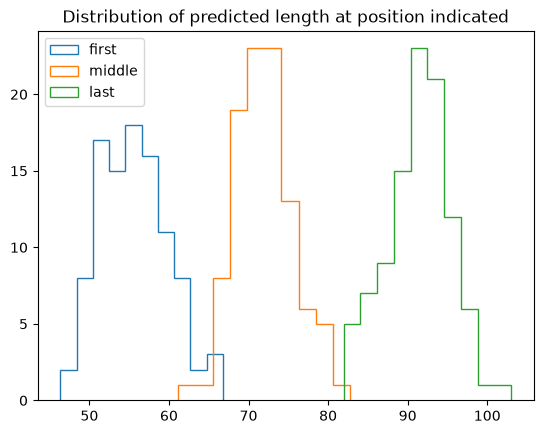

In [21]:
labels = ["first", "middle", "last"]
for i in range(3):
    _ = plt.hist(pred_vals[:, i], histtype="step", label=labels[i])
# end for
plt.legend()
plt.title("Distribution of predicted length at position indicated")

#### Get predictions from mean of all chains of Posteriors

In the same way, we now average across all chains

In [22]:
pred_vals = (
    idata_1["posterior_predictive"]
    .sel({"month_dim_0": [0, 400, 795], "draw": slice(0, 99)})
    .mean(dim="chain")["l_pred"]
    .values
)
type(pred_vals)

numpy.ndarray

Plot the results.  We expect with 4 chains, to have $1/2$ the standard deviation.

Text(0.5, 1.0, 'Distribution of predicted length at position indicated')

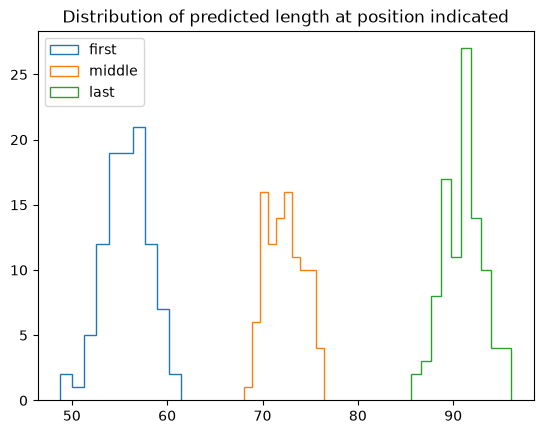

In [23]:
labels = ["first", "middle", "last"]
for i in range(3):
    _ = plt.hist(pred_vals[:, i], histtype="step", label=labels[i])
# end for
plt.legend()
plt.title("Distribution of predicted length at position indicated")

#### Conclusions

We see that the variance is the same at all positions.  What our model specified, but not what we want  (see below)


---------------------------

## Prediction of out-of-sample values

We change our _months_ array, and ask for posterior predictions again

In [24]:
with model_1:
    # set out of sample months
    oos_months = [i for i in range(31)]
    pm.set_data(
        {"month": oos_months},
    )

    post_pred = pm.sample_posterior_predictive(
        idata_1,
    )

# end with

Sampling: [l_pred]


Output()

Get the predicted lengths, averaged across chains and draws.

In [25]:
l_preds = post_pred["posterior_predictive"]["l_pred"].mean(("draw", "chain"))

Plot the:
- raw data (blue cross)
- values from out-of-sample predictions (red line)
- linear model ($y = a + b \times x$) (green points)

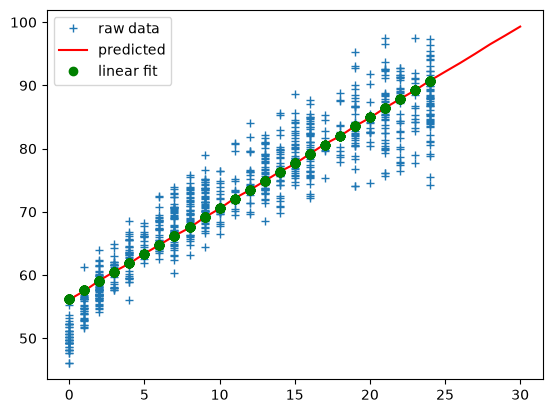

In [26]:
plt.plot(
    df["month"],
    df["length"],
    "+",
    label="raw data",
)
plt.plot(
    oos_months,
    l_preds,
    "-r",
    label="predicted",
)
plt.plot(
    df["month"],
    line_a + line_b * df["month"],
    "og",
    label="linear fit",
)
plt.legend()

------------------

### Digression: using _plot_lm_

Default plot

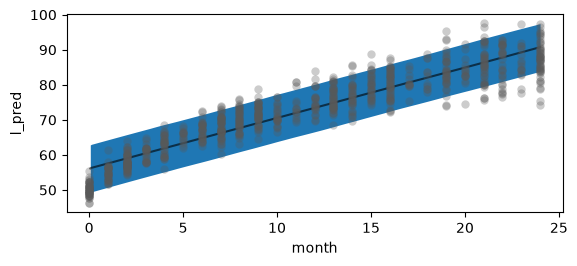

In [27]:
idata_lm = idata_1.copy()

pc = az.plot_lm(
    idata_lm,
)

Nicer looking plot

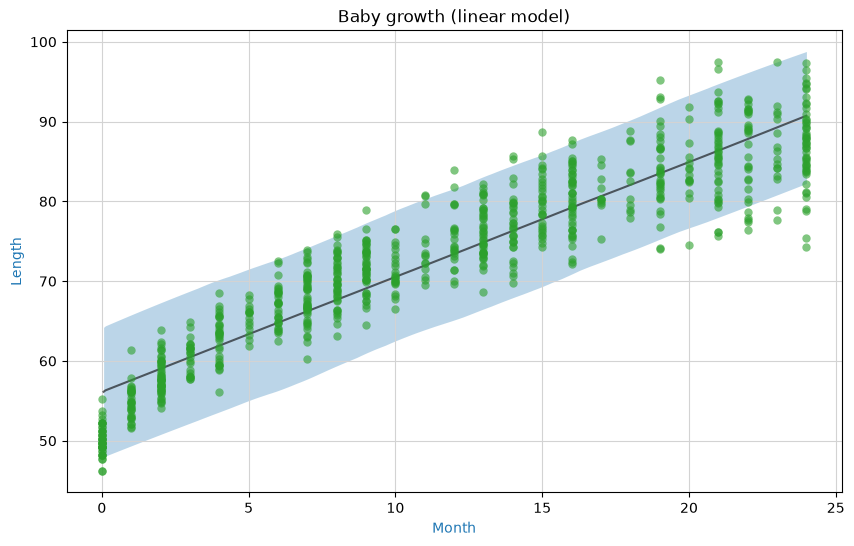

In [28]:
# do a linear model plot
# set Confidence Interval band  0.3 transparent
# set the scatter plot points to green, and make partially transparent
# set the figure size
# set the confidence interval type to HDI (High Density Interval)
# set the HDI band to contain 95% of estimated prob. densit
pc = az.plot_lm(
    idata_1,
    visuals={
        "ci_band": {"alpha": 0.3},
        "observed_scatter": {"color": "C2", "alpha": 0.6},
    },
    figure_kwargs={"figsize": (10, 6)},
    ci_kind="hdi",
    ci_prob=0.95,
)

# add a pale grid
pc.map(
    az.visuals.grid,
    axis="both",
    color="lightgray",
)

# label x axis
pc.map(
    az.visuals.labelled_x,
    text="Month",
)
# label y axis
pc.map(
    az.visuals.labelled_y,
    text="Length",
)


_ = pc.viz.figure.item().axes[0].set_title("Baby growth (linear model)")

### End of digression

-----------------------

## _sqrt_ model, constant  variance

This essentially the same model as before, except we use the sqrt of month (```intercept + slope * month**0.5```)

In [29]:
with pm.Model() as model_1:

    month = pm.Data("month", df.month)
    length = pm.Data("length", df.length)

    intercept = pm.Normal("intercept", mu=50, sigma=100)
    slope = pm.Normal("slope", mu=20, sigma=20)
    error_sd = pm.HalfCauchy("error_sd", beta=10)
    l_err0 = pm.Deterministic("l_err0", intercept + slope * month**0.5)
    l_pred = pm.Normal(
        "l_pred",
        mu=l_err0,
        sigma=error_sd,
        observed=length,
        shape=month.shape,
        dims="month_dim_0",
    )

    idata_1 = pm.sample()
# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [intercept, slope, error_sd]


Output()

Visualize model

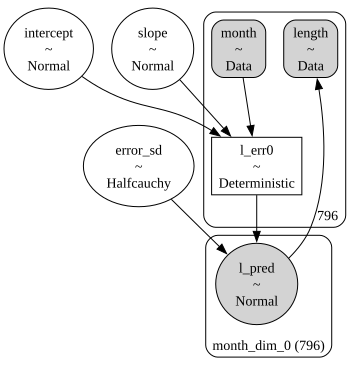

In [30]:
pm.model_to_graphviz(model_1)

Check for model issues (None)

In [31]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


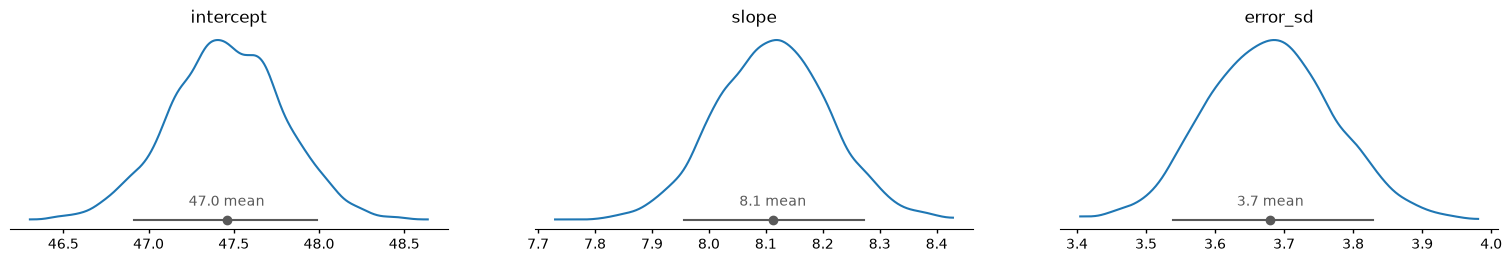

In [32]:
az.plot_dist(idata_1, var_names=["intercept", "slope", "error_sd"])

Get model parameters for plotting

In [33]:
results = az.summary(idata_1, var_names=["intercept", "slope"])
results

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,47.46,0.33,47,48,941,1232,1.00,0.011,0.0075
slope,8.112,0.099,8,8.3,964,1238,1.00,0.0032,0.0024


In [34]:
line_a = results.loc["intercept", "mean"]
line_b = results.loc["slope", "mean"]
line_a, line_b

(np.float64(47.45810407495688), np.float64(8.112174504009483))

Plot results - fit looks better

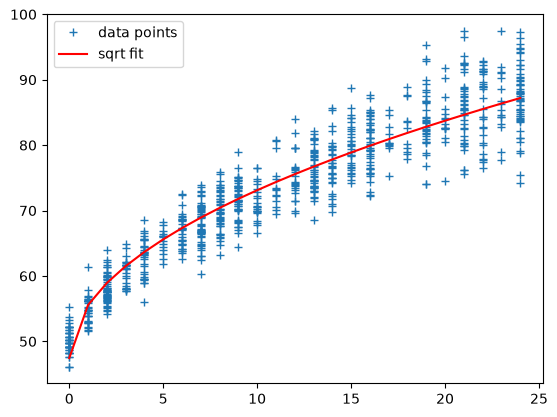

In [35]:
plt.plot(df["month"], df["length"], "+", label="data points")
plt.plot(df["month"], line_a + line_b * df["month"] ** 0.5, "-r", label="sqrt fit")
plt.legend()

------------------------------

#### Get predictions from  Posteriors

As before, we want to see the spread of predicted _length_ values for three positions on the x axis

First set up required data structures

In [36]:
# Sample posterior predictive and append it automatically
with model_1:
    pm.sample_posterior_predictive(idata_1, extend_inferencedata=True)
# end with

Sampling: [l_pred]


Output()

Get the data to plot

In [37]:
pred_vals = (
    idata_1["posterior_predictive"]
    .sel({"month_dim_0": [0, 400, 795], "draw": slice(0, 99)})
    .mean(dim="chain")["l_pred"]
    .values
)
type(pred_vals)

numpy.ndarray

Do the plotting

Text(0.5, 1.0, 'Distribution of predicted length at position indicated')

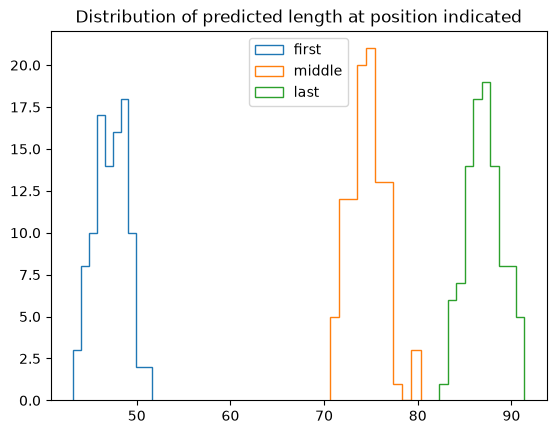

In [38]:
labels = ["first", "middle", "last"]
for i in range(3):
    _ = plt.hist(pred_vals[:, i], histtype="step", label=labels[i])
# end for
plt.legend()
plt.title("Distribution of predicted length at position indicated")

Still a constant variance

--------------------------

## Final model

In our final model, we have _length_ with a $sqrt (month)$ dependence, and noise standard deviation to grow linearly with _month_ (```error_0 + error_slope * month```)

In [39]:
with pm.Model() as model_1:

    month = pm.Data("month", df.month)
    length = pm.Data("length", df.length)

    intercept = pm.Normal("intercept", mu=50, sigma=100)
    slope = pm.Normal("slope", mu=20, sigma=20)

    error_0 = pm.HalfNormal("error_0", sigma=10)
    error_slope = pm.HalfNormal("error_slope", sigma=10)

    l_err0 = pm.Deterministic("l_err0", intercept + slope * month**0.5)
    error_sd = pm.Deterministic("error_sd", error_0 + error_slope * month)

    l_pred = pm.Normal(
        "l_pred",
        mu=l_err0,
        sigma=error_sd,
        observed=length,
        shape=month.shape,
        dims="month_dim_0",
    )

    idata_1 = pm.sample()
# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [intercept, slope, error_0, error_slope]


Output()

Visualize model

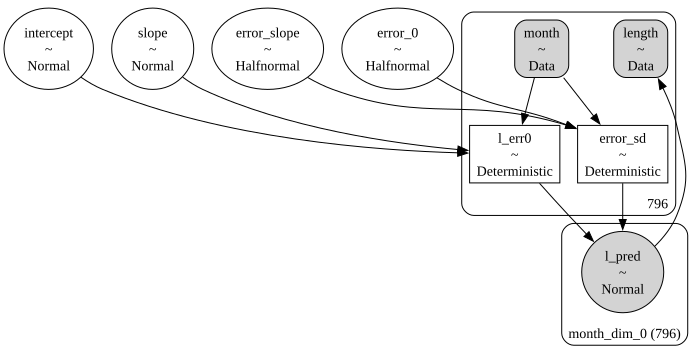

In [40]:
pm.model_to_graphviz(model_1)

Check for issues (None)

In [41]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


Get model parameters

In [42]:
az.summary(idata_1, var_names=["intercept", "slope"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,48.05,0.234,48,48,1293,1580,1.00,0.0065,0.0044
slope,7.867,0.085,7.7,8,1265,1603,1.00,0.0024,0.0016


In [43]:
line_a = results.loc["intercept", "mean"]
line_b = results.loc["slope", "mean"]
line_a, line_b

(np.float64(47.45810407495688), np.float64(8.112174504009483))

Visualize fit (looks OK)

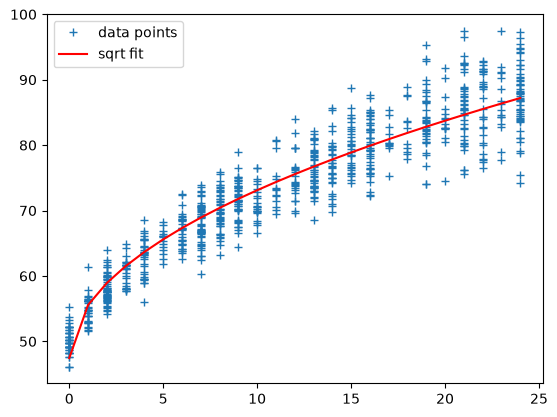

In [44]:
plt.plot(df["month"], df["length"], "+", label="data points")
plt.plot(df["month"], line_a + line_b * df["month"] ** 0.5, "-r", label="sqrt fit")
plt.legend()

Check distributions of key parameters.  We can see thet the length standard deviation grows by $0.11$ each month

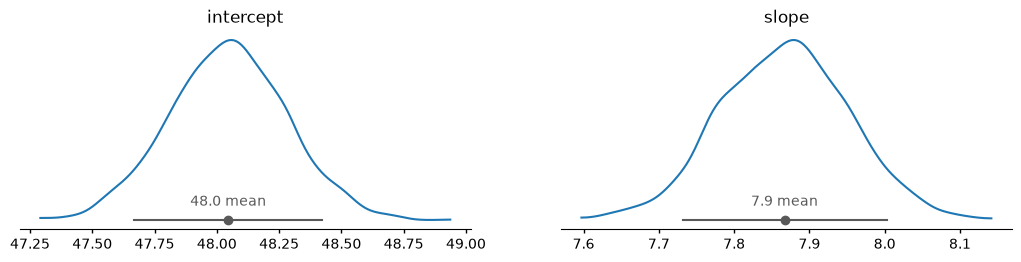

In [45]:
az.plot_dist(
    idata_1,
    var_names=[
        "intercept",
        "slope",
    ],
)

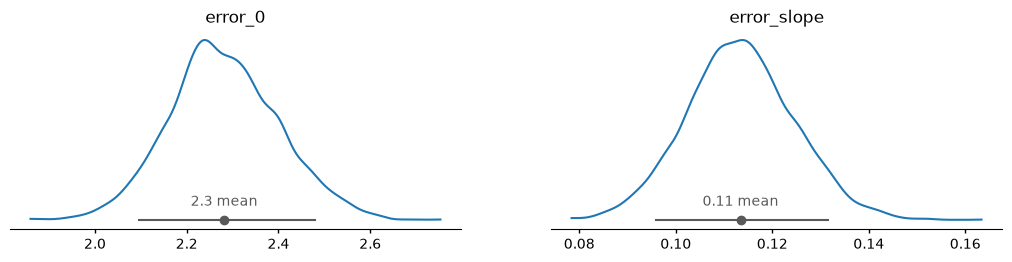

In [46]:
az.plot_dist(
    idata_1,
    var_names=[
        "error_0",
        "error_slope",
    ],
)

#### Check variance is actually increasing

Display initial model data structures

In [47]:
idata_1

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:         (chain: 4, draw: 1000, l_err0_dim_0: 796,
│                            error_sd_dim_0: 796)
│       Coordinates:
│         * chain           (chain) int64 32B 0 1 2 3
│         * draw            (draw) int64 8kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
│         * l_err0_dim_0    (l_err0_dim_0) int64 6kB 0 1 2 3 4 5 ... 791 792 793 794 795
│         * error_sd_dim_0  (error_sd_dim_0) int64 6kB 0 1 2 3 4 ... 791 792 793 794 795
│       Data variables:
│           intercept       (chain, draw) float64 32kB 47.92 48.0 48.08 ... 48.03 48.03
│           slope           (chain, draw) float64 32kB 7.892 7.868 7.873 ... 7.812 7.94
│           error_0         (chain, draw) float64 32kB 2.326 2.262 2.33 ... 2.173 2.231
│           error_slope     (chain, draw) float64 32kB 0.1046 0.1269 ... 0.1248 0.1191
│           l_err0          (chain, draw, l_err0_dim_0) float64 25MB 47.92 ... 86.92
│           error_sd        (chain, draw, error_sd_dim_0) float64 25MB 2.326 ... 5.09
│       Attributes:
│           created_at:                 2026-10-24T00:10:27.133980+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.4556581974029541
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 2 2 3 3 ... 2 2 2 2 2
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.626 0.6175 ... 0.6373
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.6506 ... 0.6255
│           mean_tree_accept          (chain, draw) float64 32kB 0.9597 ... 0.8469
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 1.947 2.642 ... 7.311
│           transformation_index      (chain, draw) int64 32kB 339 339 339 ... 336 336
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-10-24T00:10:27.110222+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           month        (month_dim_0) int32 3kB 0 0 0 0 0 0 0 ... 24 24 24 24 24 24 24
│       Attributes:
│           created_at:                 2026-10-24T00:10:27.128738+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_l

Create the Posterior predictions  (we have 100 samples at each of 3 x axis positions)

In [48]:
# Sample posterior predictive and append it automatically
with model_1:
    pm.sample_posterior_predictive(idata_1, extend_inferencedata=True)
# end with

pred_vals = (
    idata_1["posterior_predictive"]
    .sel({"month_dim_0": [0, 400, 795], "draw": slice(0, 99)})
    .mean(dim="chain")["l_pred"]
    .values
)

Sampling: [l_pred]


Output()

Plot the prediction distributions: we can see variance growing as we move left to right

Text(0.5, 1.0, 'Distribution of predicted length at position indicated')

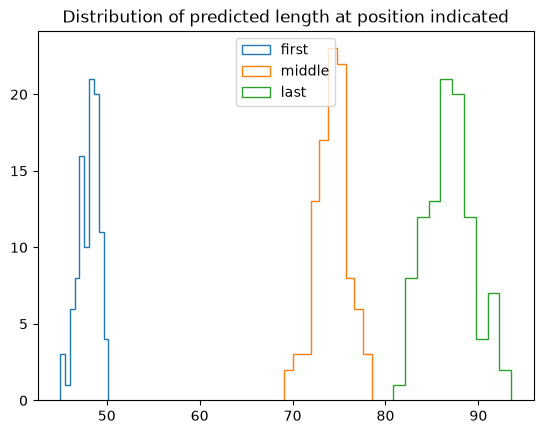

In [49]:
labels = ["first", "middle", "last"]
for i in range(3):
    _ = plt.hist(pred_vals[:, i], histtype="step", label=labels[i])
# end for
plt.legend()
plt.title("Distribution of predicted length at position indicated")

Show the data structures

In [50]:
idata_1

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:         (chain: 4, draw: 1000, l_err0_dim_0: 796,
│                            error_sd_dim_0: 796)
│       Coordinates:
│         * chain           (chain) int64 32B 0 1 2 3
│         * draw            (draw) int64 8kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
│         * l_err0_dim_0    (l_err0_dim_0) int64 6kB 0 1 2 3 4 5 ... 791 792 793 794 795
│         * error_sd_dim_0  (error_sd_dim_0) int64 6kB 0 1 2 3 4 ... 791 792 793 794 795
│       Data variables:
│           intercept       (chain, draw) float64 32kB 47.92 48.0 48.08 ... 48.03 48.03
│           slope           (chain, draw) float64 32kB 7.892 7.868 7.873 ... 7.812 7.94
│           error_0         (chain, draw) float64 32kB 2.326 2.262 2.33 ... 2.173 2.231
│           error_slope     (chain, draw) float64 32kB 0.1046 0.1269 ... 0.1248 0.1191
│           l_err0          (chain, draw, l_err0_dim_0) float64 25MB 47.92 ... 86.92
│           error_sd        (chain, draw, error_sd_dim_0) float64 25MB 2.326 ... 5.09
│       Attributes:
│           created_at:                 2026-10-24T00:10:27.133980+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.4556581974029541
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 2 2 3 3 ... 2 2 2 2 2
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.626 0.6175 ... 0.6373
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.6506 ... 0.6255
│           mean_tree_accept          (chain, draw) float64 32kB 0.9597 ... 0.8469
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 1.947 2.642 ... 7.311
│           transformation_index      (chain, draw) int64 32kB 339 339 339 ... 336 336
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-10-24T00:10:27.110222+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           month        (month_dim_0) int32 3kB 0 0 0 0 0 0 0 ... 24 24 24 24 24 24 24
│       Attributes:
│           created_at:                 2026-10-24T00:10:42.178244+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_l

#### Visualize growth of standard deviation of length

Get data for plotting

In [51]:
post_vals = idata_1["posterior"].mean(dim=["draw", "chain"])["error_sd"].values

In [52]:
len(post_vals)

796

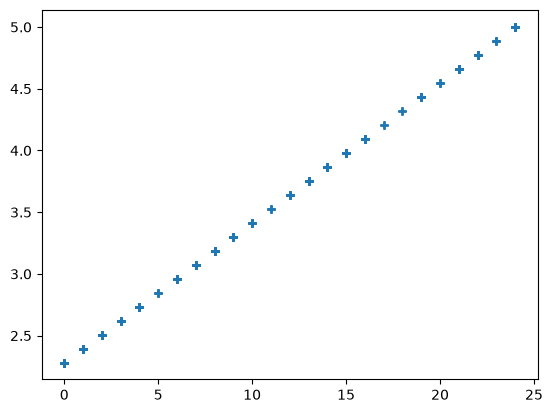

In [53]:
plt.plot(df.month, post_vals, "+")

Indeed standard deviation grows linearly

----------------------------------

## Final model predictions

We now look at predictions for all months out to month 40

Change the _month_ data structure to trigger calculations

In [54]:
with model_1:
    # set out of sample months
    oos_months = [i for i in range(41)]
    pm.set_data(
        {"month": oos_months},
    )

    post_pred = pm.sample_posterior_predictive(
        idata_1, var_names=["l_pred", "error_sd"]
    )

# end with

Sampling: [l_pred]


Output()

Show the new data structures

In [55]:
post_pred

<xarray.DataTree>
Group: /
├── Group: /posterior_predictive
│       Dimensions:         (chain: 4, draw: 1000, month_dim_0: 41, error_sd_dim_0: 41)
│       Coordinates:
│         * chain           (chain) int64 32B 0 1 2 3
│         * draw            (draw) int64 8kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
│         * month_dim_0     (month_dim_0) int64 328B 0 1 2 3 4 5 6 ... 35 36 37 38 39 40
│         * error_sd_dim_0  (error_sd_dim_0) int64 328B 0 1 2 3 4 5 ... 36 37 38 39 40
│       Data variables:
│           l_pred          (chain, draw, month_dim_0) float64 1MB 49.71 58.65 ... 99.01
│           error_sd        (chain, draw, error_sd_dim_0) float64 1MB 2.326 ... 6.995
│       Attributes:
│           created_at:                 2026-10-24T00:10:43.630993+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:      (month_dim_0: 796)
│       Coordinates:
│         * month_dim_0  (month_dim_0) int64 6kB 0 1 2 3 4 5 ... 790 791 792 793 794 795
│       Data variables:
│           l_pred       (month_dim_0) float64 6kB 49.19 51.22 51.22 ... 97.35 94.19
│       Attributes:
│           created_at:                 2026-10-24T00:10:43.645013+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group: /constant_data
        Dimensions:      (month_dim_0: 41)
        Coordinates:
          * month_dim_0  (month_dim_0) int64 328B 0 1 2 3 4 5 6 ... 34 35 36 37 38 39 40
        Data variables:
            month        (month_dim_0) int32 164B 0 1 2 3 4 5 6 ... 34 35 36 37 38 39 40
        Attributes:
            created_at:                 2026-10-24T00:10:43.652156+00:00
            creation_library:           ArviZ
            creation_library_version:   1.3.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.1
            sample_dims:                []

Get the data for plotting

In [56]:
l_preds = post_pred["posterior_predictive"]["l_pred"].mean(("draw", "chain"))

error_sds = post_pred["posterior_predictive"]["error_sd"].mean(("draw", "chain"))

Get the model key parameters

In [57]:
results = az.summary(idata_1, var_names=["intercept", "slope"])
results

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,48.05,0.234,48,48,1293,1580,1.00,0.0065,0.0044
slope,7.867,0.085,7.7,8,1265,1603,1.00,0.0024,0.0016


In [58]:
line_a = results.loc["intercept", "mean"]
line_b = results.loc["slope", "mean"]
line_a, line_b

(np.float64(48.045530742250314), np.float64(7.866914155716518))

Plot the result

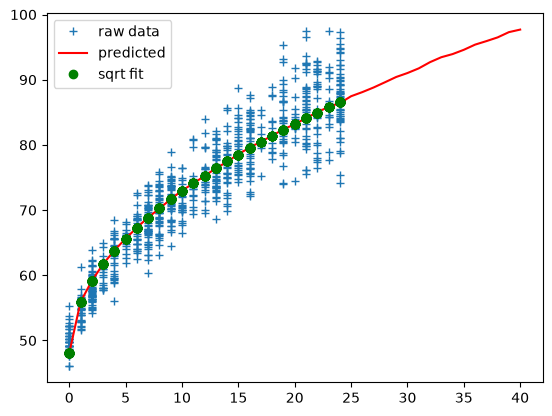

In [59]:
plt.plot(
    df["month"],
    df["length"],
    "+",
    label="raw data",
)
plt.plot(
    oos_months,
    l_preds,
    "-r",
    label="predicted",
)
plt.plot(
    df["month"],
    line_a + line_b * df["month"] ** 0.5,
    "og",
    label="sqrt fit",
)
plt.legend()

#### Enhanced plot

We draw lines at 1.96 standard deviations above and below our fitted growth curve (95% lines)

Text(0.5, 1.0, 'sqrt length, linear std ')

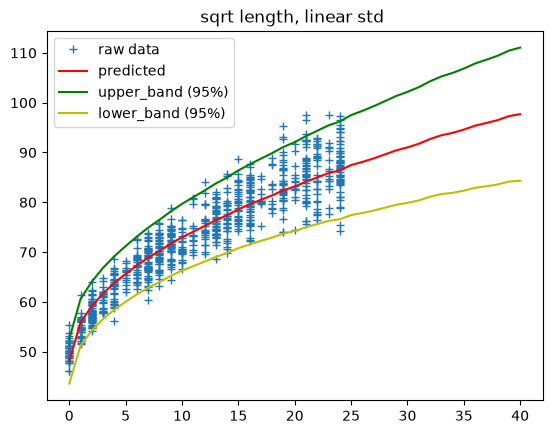

In [60]:
plt.plot(
    df["month"],
    df["length"],
    "+",
    label="raw data",
)
plt.plot(
    oos_months,
    l_preds,
    "-r",
    label="predicted",
)

upper_line = [x + 1.96 * y for x, y in zip(l_preds.values, error_sds.values)]
lower_line = [x - 1.96 * y for x, y in zip(l_preds.values, error_sds.values)]
plt.plot(
    oos_months,
    upper_line,
    "-g",
    label="upper_band (95%)",
)
plt.plot(
    oos_months,
    lower_line,
    "-y",
    label="lower_band (95%)",
)
plt.legend()
plt.title("sqrt length, linear std ")

### Check model execution (did all of possible parameter space get explored?)

In a perfect world, the two curves should overlap.  However, I have used the default sampling parameters (```idata_1 = pm.sample()```), so I am not too worried

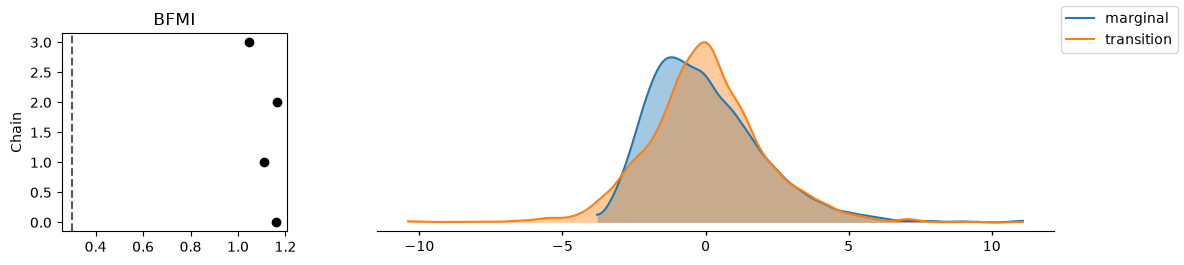

In [61]:
pc = az.plot_energy(
    idata_1,
)

---------------------

## Conclusions

I spent a lot more time fighting PyMC and ArViz documentation (especially the behavior of dimension names), more so than actually understanding the model.  What didn't help was that Google AI and search are totally poisoned by the significant changes in function names, etc in the history of the packages.  Be aware and make sure you are reading the latest version of the manuals.

Also don't be lazy (like me), and do read the PyMC document on data structures, to make sure you understand how to extract data, and how to create ancillary data structures 

-------------
## Reproducability

In [62]:
%load_ext watermark

The watermark extension is already loaded. To reload it, use:
  %reload_ext watermark


In [63]:
%watermark

Last updated: 2026-10-24T10:10:44.734542+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [64]:
%watermark -h -iv -co

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
pandas    : 3.0.5
preliz    : 0.28.0
pymc      : 6.3.1
xarray    : 2026.7.0

